# Laboratorio 5 — Análisis de datos de entrada y ajuste de datos a distribuciones de probabilidad

**Curso:** Simulación Computacional — Universidad de los Llanos
**Guía:** FO-DOC-112, Práctica N.º 04 (*Input data and goodness of fit*)

Este notebook desarrolla las tres partes de la guía sobre los cuatro conjuntos de datos
`dataset-A.txt`, `dataset-B.txt`, `dataset-C.txt` y `dataset-D.txt`:

1. **5.1** Estadística descriptiva e histogramas (20 *bins*).
2. **5.2** Análisis de datos de entrada: correlaciones de retraso, diagrama de dispersión,
   patrón de hora de llegada, conteo de llegadas por intervalo y media móvil, para evaluar
   los supuestos de independencia y estacionariedad.
3. **5.3** Ajuste de curvas con nueve distribuciones de probabilidad y evaluación de la bondad
   de ajuste con SSE, AIC y BIC; selección de las tres mejores por conjunto de datos.

In [1]:
import os, math, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as st

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.titleweight": "bold", "font.size": 10})
os.makedirs("imagenes", exist_ok=True)
os.makedirs("tablas", exist_ok=True)

## Carga de los conjuntos de datos

Si los archivos no están en el directorio de trabajo (por ejemplo, en Google Colab) se descargan
directamente desde los enlaces de Google Drive indicados en la guía.

In [2]:
DRIVE_IDS = {
    "A": "1xYqg1BCxDQH542_Njz0s7tzay6dIG_VO",
    "B": "1W-pHCurCQFaJ_ydv5BDYsWDxg2-2dxZX",
    "C": "10B8Y6i1H_1J8cFeLoufWTVTtztthYSXj",
    "D": "1LysY3NL4fFamvChMtPQNrKaXaNMfN_44",
}

def cargar_dataset(letra):
    nombre = f"dataset-{letra}.txt"
    if not os.path.exists(nombre):
        try:
            import gdown
            gdown.download(id=DRIVE_IDS[letra], output=nombre, quiet=True)
        except Exception as e:
            print("No se pudo descargar automáticamente:", e)
            from google.colab import files
            files.upload()
    return np.loadtxt(nombre)

datos = {k: cargar_dataset(k) for k in "ABCD"}
for k, x in datos.items():
    print(f"Dataset {k}: n = {len(x)}, primeros valores: {np.round(x[:5], 4)}")

Dataset A: n = 200, primeros valores: [0.021  0.0814 0.1562 0.1494 0.1934]
Dataset B: n = 200, primeros valores: [0.1521 0.0356 0.804  0.0073 0.0352]
Dataset C: n = 200, primeros valores: [ 1.6159  0.9267  1.1669 16.6765 19.678 ]
Dataset D: n = 200, primeros valores: [0.4637 0.2135 8.4562 8.1297 1.3658]


## 5.1 Estadística descriptiva

Para cada conjunto se calculan el tamaño de muestra, mínimo, máximo, media, varianza y desviación
estándar muestrales ($n-1$ en el denominador) y los percentiles 25 %, 50 % y 75 %. Se agregan la
asimetría (*skewness*) y la curtosis (exceso, de Fisher) porque son las medidas consultadas en la
Sección 2 y ayudan a anticipar la familia de distribuciones candidata.

In [3]:
def describir(x):
    q1, q2, q3 = np.percentile(x, [25, 50, 75])
    return {
        "Tamaño de la muestra": len(x),
        "Mínimo": x.min(),
        "Máximo": x.max(),
        "Media": x.mean(),
        "Varianza": x.var(ddof=1),
        "Desviación estándar": x.std(ddof=1),
        "Percentil 25% (Q1)": q1,
        "Percentil 50% (Q2, mediana)": q2,
        "Percentil 75% (Q3)": q3,
        "Asimetría (skewness)": st.skew(x),
        "Curtosis (exceso)": st.kurtosis(x),
    }

tabla1 = pd.DataFrame({f"Dataset {k}": describir(x) for k, x in datos.items()})
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
tabla1

,Dataset A,Dataset B,Dataset C,Dataset D
Tamaño de la muestra,200.0000,200.0000,200.0000,200.0000
Mínimo,0.0210,0.0001,0.9267,0.1115
Máximo,0.2990,1.5513,"6,669.8531",17.9670
Media,0.1950,0.2054,762.3938,2.0605
Varianza,0.0019,0.0525,"852,169.6630",5.4130
Desviación estándar,0.0438,0.2291,923.1304,2.3266
Percentil 25% (Q1),0.1638,0.0463,152.9121,0.6343
"Percentil 50% (Q2, mediana)",0.1921,0.1377,455.5576,1.4064
Percentil 75% (Q3),0.2301,0.2902,"1,028.5909",2.5289
Asimetría (skewness),-0.2895,2.4064,2.4821,3.1596


In [4]:
# Tabla 1 en LaTeX para el informe
def fmt(v, fila):
    if fila == "Tamaño de la muestra":
        return f"{int(v)}"
    return f"{v:.4f}" if abs(v) < 1000 else f"{v:,.2f}".replace(",", "\\,")

lineas = []
for fila, vals in tabla1.iterrows():
    lineas.append(fila + " & " + " & ".join(fmt(v, fila) for v in vals) + r" \\")
with open("tablas/tabla1.tex", "w") as f:
    f.write("\n".join(lineas))
print("\n".join(lineas))

Tamaño de la muestra & 200 & 200 & 200 & 200 \\
Mínimo & 0.0210 & 0.0001 & 0.9267 & 0.1115 \\
Máximo & 0.2990 & 1.5513 & 6\,669.85 & 17.9670 \\
Media & 0.1950 & 0.2054 & 762.3938 & 2.0605 \\
Varianza & 0.0019 & 0.0525 & 852\,169.66 & 5.4130 \\
Desviación estándar & 0.0438 & 0.2291 & 923.1304 & 2.3266 \\
Percentil 25% (Q1) & 0.1638 & 0.0463 & 152.9121 & 0.6343 \\
Percentil 50% (Q2, mediana) & 0.1921 & 0.1377 & 455.5576 & 1.4064 \\
Percentil 75% (Q3) & 0.2301 & 0.2902 & 1\,028.59 & 2.5289 \\
Asimetría (skewness) & -0.2895 & 2.4064 & 2.4821 & 3.1596 \\
Curtosis (exceso) & 0.3090 & 7.9741 & 9.1009 & 14.0891 \\


### Histogramas con 20 particiones

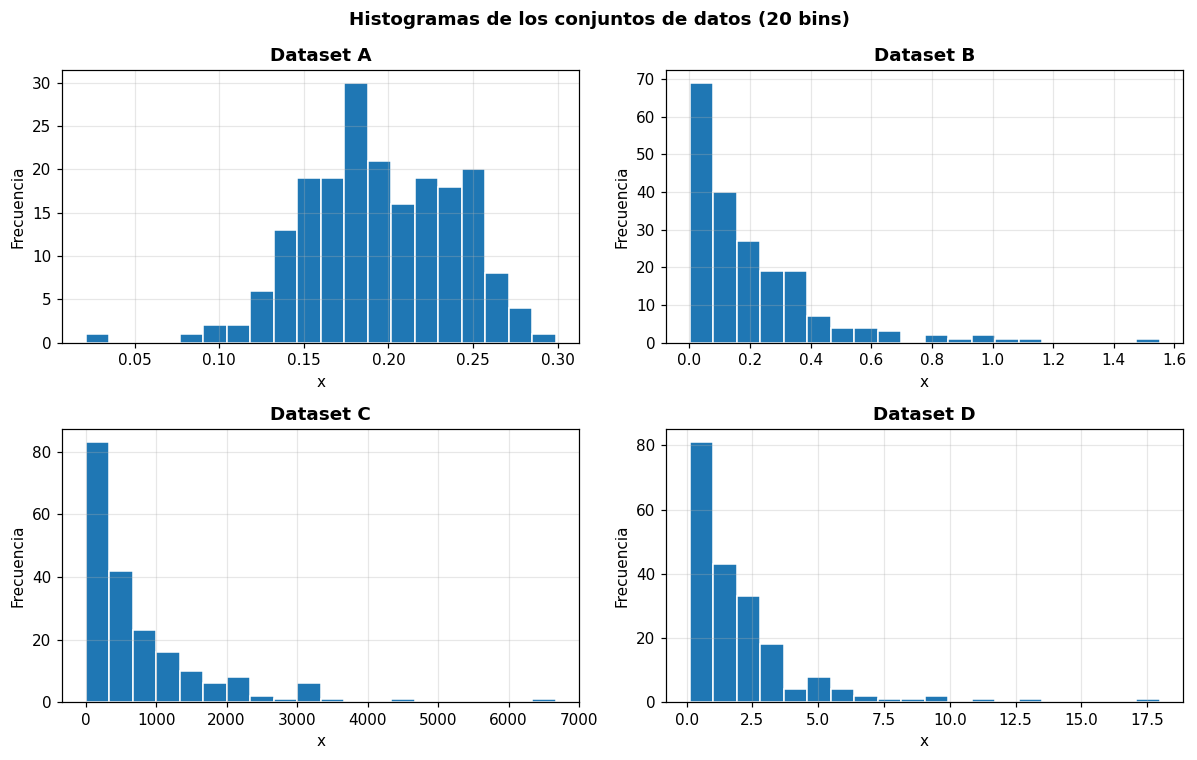

In [5]:
fig, axs = plt.subplots(2, 2, figsize=(11, 7))
for ax, (k, x) in zip(axs.ravel(), datos.items()):
    ax.hist(x, bins=20, color="#1f77b4", edgecolor="white")
    ax.set_title(f"Dataset {k}")
    ax.set_xlabel("x"); ax.set_ylabel("Frecuencia")
fig.suptitle("Histogramas de los conjuntos de datos (20 bins)", fontweight="bold")
fig.tight_layout()
fig.savefig("imagenes/histogramas.png", dpi=150, bbox_inches="tight")
plt.show()

## 5.2 Análisis de datos de entrada: independencia y estacionariedad

Siguiendo el notebook *Example. Input Data Analysis* y la Sección 3.4 de Banks (1998), cada
secuencia se interpreta como una muestra ordenada en el tiempo de un proceso estocástico (en los
patrones de llegada se interpreta además como tiempos entre llegadas). Se construyen cinco gráficas
por conjunto de datos:

- **(a) Correlaciones de retraso estimadas**: $\hat\rho_k$ para $k=1,\dots,25$, con bandas
  $\pm 2/\sqrt{n}$ (aprox. 95 %). Valores fuera de la banda indican dependencia serial.
- **(b) Diagrama de dispersión** de $(x_i, x_{i+1})$: una nube sin estructura sugiere independencia.
- **(c) Patrón de hora de llegada**: número acumulado de llegadas $N(t)$ con $t_i=\sum_{j\le i}x_j$.
  Un proceso estacionario produce una recta; un cambio de pendiente indica cambio de tasa.
- **(d) Conteo de llegadas vs. intervalos**: el horizonte $[0,t_n]$ se parte en 20 intervalos iguales y
  se cuentan las llegadas en cada uno. Con tasa constante los conteos fluctúan alrededor de $n/20$.
- **(e) Media móvil** con ventanas de 10 y 20 observaciones: una tendencia o un cambio de nivel
  revela no estacionariedad en la media.

Se complementan con estadísticos numéricos: $\hat\rho_1$, prueba de Ljung–Box ($h=10$ retardos),
prueba de rachas sobre la mediana y correlación de Spearman entre el índice y el valor (tendencia).

In [6]:
def autocorr(x, max_lag=25):
    x = np.asarray(x, float); n = len(x); xm = x - x.mean()
    den = np.sum(xm**2)
    return np.array([np.sum(xm[:-k] * xm[k:]) / den for k in range(1, max_lag + 1)])

def ljung_box(x, h=10):
    n = len(x); r = autocorr(x, h)
    Q = n * (n + 2) * np.sum(r**2 / (n - np.arange(1, h + 1)))
    return Q, 1 - st.chi2.cdf(Q, h)

def runs_test(x):
    # prueba de rachas (Wald–Wolfowitz) por encima/debajo de la mediana
    med = np.median(x); s = x > med
    n1, n2 = s.sum(), (~s).sum()
    R = 1 + np.sum(s[1:] != s[:-1])
    mu = 1 + 2 * n1 * n2 / (n1 + n2)
    var = 2 * n1 * n2 * (2 * n1 * n2 - n1 - n2) / ((n1 + n2) ** 2 * (n1 + n2 - 1))
    Z = (R - mu) / math.sqrt(var)
    return R, Z, 2 * (1 - st.norm.cdf(abs(Z)))

MAX_LAG = 25
resumen = {}
for k, x in datos.items():
    n = len(x); r = autocorr(x, MAX_LAG)
    Q, pQ = ljung_box(x)
    R, Z, pR = runs_test(x)
    rho, prho = st.spearmanr(np.arange(n), x)
    resumen[k] = {"n": n, "rho1": r[0], "fuera_banda": int(np.sum(np.abs(r) > 2 / math.sqrt(n))),
                  "LB_Q": Q, "LB_p": pQ, "rachas_R": R, "rachas_Z": Z, "rachas_p": pR,
                  "spearman_rho": rho, "spearman_p": prho,
                  "media_1a_mitad": x[: n // 2].mean(), "media_2a_mitad": x[n // 2 :].mean(),
                  "var_1a_mitad": x[: n // 2].var(ddof=1), "var_2a_mitad": x[n // 2 :].var(ddof=1)}
tabla_indep = pd.DataFrame(resumen).T
tabla_indep

,n,rho1,fuera_banda,LB_Q,LB_p,rachas_R,rachas_Z,rachas_p,spearman_rho,spearman_p,media_1a_mitad,media_2a_mitad,var_1a_mitad,var_2a_mitad
A,200.0000,0.4922,5.0000,83.6925,0.0000,78.0000,-3.2609,0.0011,-0.1048,0.1397,0.1988,0.1913,0.0021,0.0017
B,200.0000,-0.0923,0.0000,6.9414,0.7310,116.0000,2.1267,0.0334,-0.0035,0.9610,0.2050,0.2058,0.0557,0.0498
C,200.0000,0.2084,10.0000,110.8847,0.0000,84.0000,-2.4102,0.0159,0.6034,0.0000,417.5578,"1,107.2299","364,320.7683","1,108,400.3071"
D,200.0000,-0.0024,0.0000,2.7106,0.9874,110.0000,1.2760,0.2020,-0.1171,0.0987,2.2830,1.8380,5.1976,5.5830


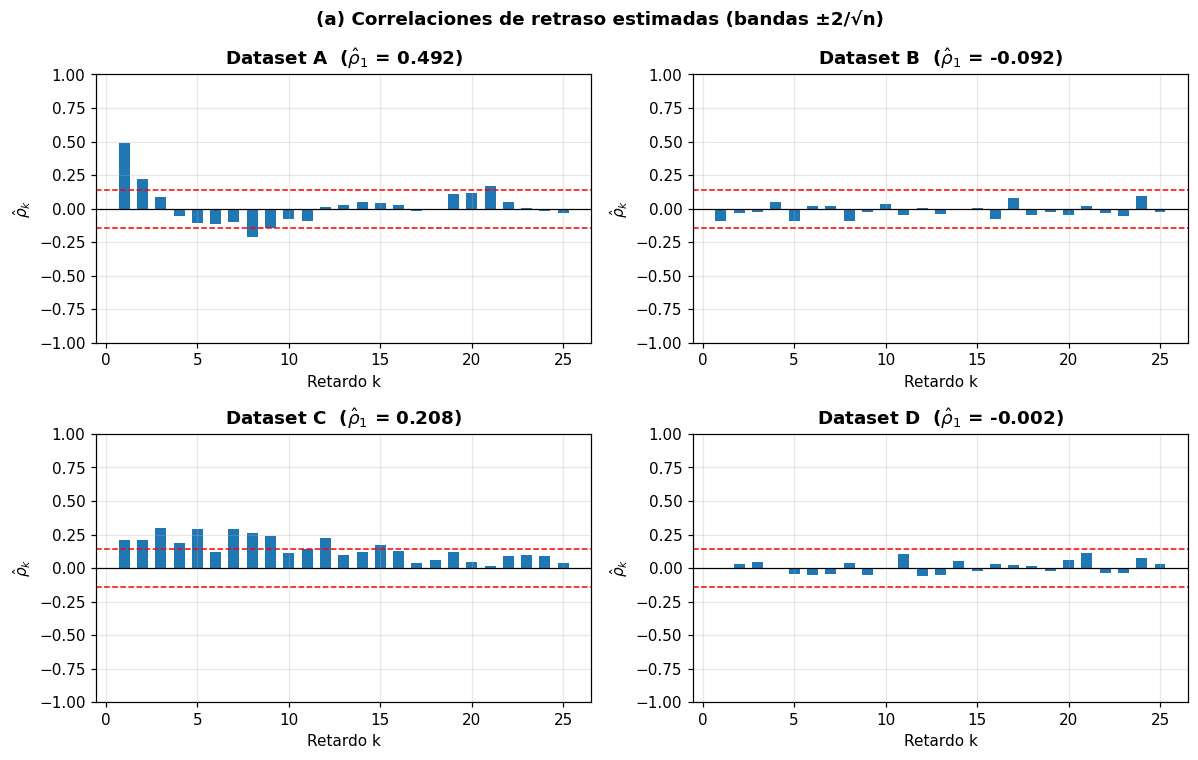

In [7]:
# (a) Correlaciones de retraso estimadas
fig, axs = plt.subplots(2, 2, figsize=(11, 7))
for ax, (k, x) in zip(axs.ravel(), datos.items()):
    n = len(x); r = autocorr(x, MAX_LAG); lags = np.arange(1, MAX_LAG + 1)
    ax.bar(lags, r, width=0.6, color="#1f77b4")
    ax.axhline(2 / math.sqrt(n), ls="--", color="red", lw=1); ax.axhline(-2 / math.sqrt(n), ls="--", color="red", lw=1)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(f"Dataset {k}  ($\\hat\\rho_1$ = {r[0]:.3f})"); ax.set_xlabel("Retardo k"); ax.set_ylabel(r"$\hat\rho_k$")
    ax.set_ylim(-1, 1)
fig.suptitle("(a) Correlaciones de retraso estimadas (bandas ±2/√n)", fontweight="bold")
fig.tight_layout(); fig.savefig("imagenes/lag_correlations.png", dpi=150, bbox_inches="tight"); plt.show()

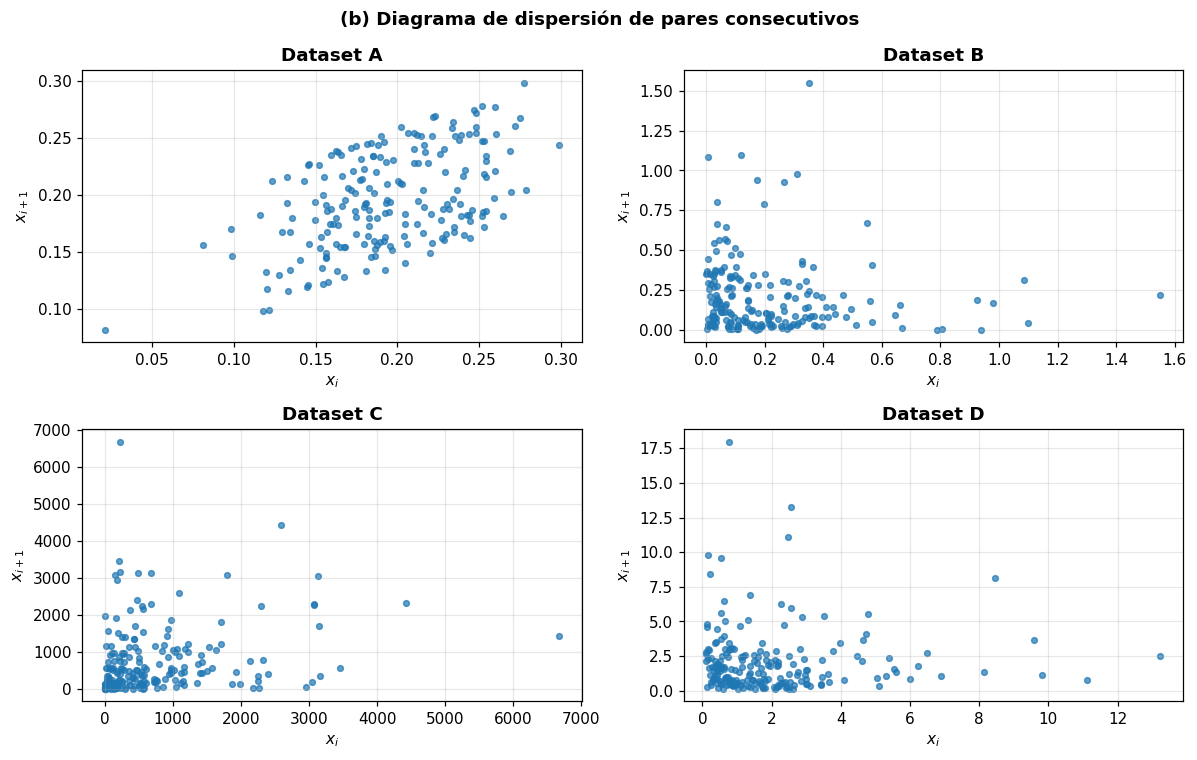

In [8]:
# (b) Diagrama de dispersión x_i vs x_{i+1}
fig, axs = plt.subplots(2, 2, figsize=(11, 7))
for ax, (k, x) in zip(axs.ravel(), datos.items()):
    ax.scatter(x[:-1], x[1:], s=14, alpha=0.7, color="#1f77b4")
    ax.set_title(f"Dataset {k}"); ax.set_xlabel("$x_i$"); ax.set_ylabel("$x_{i+1}$")
fig.suptitle("(b) Diagrama de dispersión de pares consecutivos", fontweight="bold")
fig.tight_layout(); fig.savefig("imagenes/scatter.png", dpi=150, bbox_inches="tight"); plt.show()

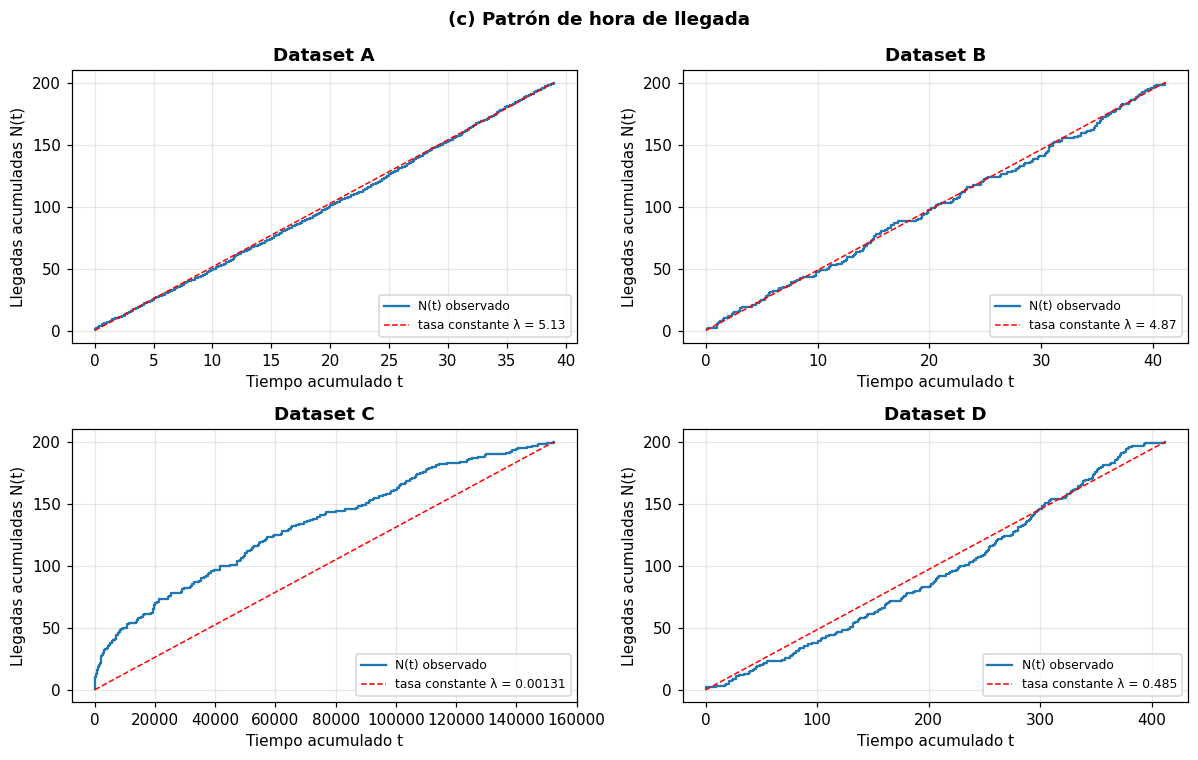

In [9]:
# (c) Patrón de hora de llegada: N(t) acumulado interpretando x_i como tiempos entre llegadas
fig, axs = plt.subplots(2, 2, figsize=(11, 7))
for ax, (k, x) in zip(axs.ravel(), datos.items()):
    t = np.cumsum(x); n = len(x)
    ax.step(t, np.arange(1, n + 1), where="post", color="#1f77b4", lw=1.5, label="N(t) observado")
    ax.plot([0, t[-1]], [0, n], "r--", lw=1, label=f"tasa constante λ = {n / t[-1]:.3g}")
    ax.set_title(f"Dataset {k}"); ax.set_xlabel("Tiempo acumulado t"); ax.set_ylabel("Llegadas acumuladas N(t)")
    ax.legend(fontsize=8, loc="lower right")
fig.suptitle("(c) Patrón de hora de llegada", fontweight="bold")
fig.tight_layout(); fig.savefig("imagenes/arrival_pattern.png", dpi=150, bbox_inches="tight"); plt.show()

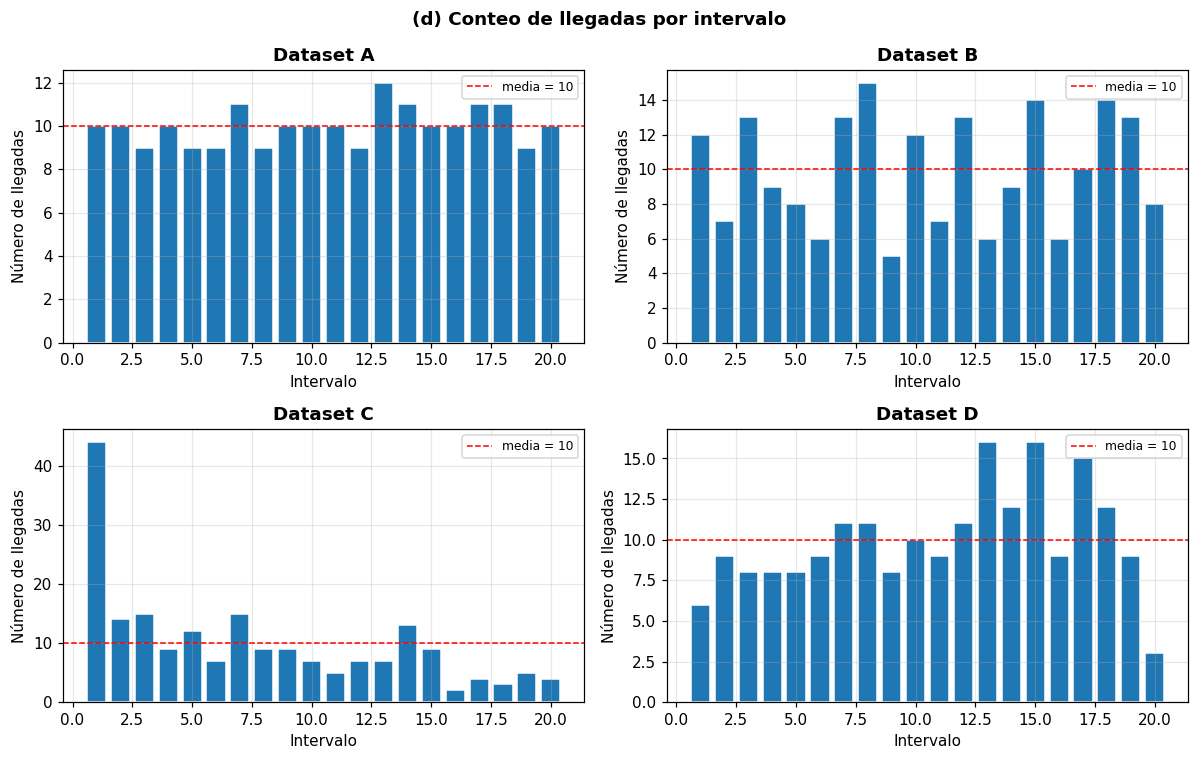

,I1,I2,I3,I4,I5,I6,I7,I8,I9,I10,I11,I12,I13,I14,I15,I16,I17,I18,I19,I20
A,10,10,9,10,9,9,11,9,10,10,10,9,12,11,10,10,11,11,9,10
B,12,7,13,9,8,6,13,15,5,12,7,13,6,9,14,6,10,14,13,8
C,44,14,15,9,12,7,15,9,9,7,5,7,7,13,9,2,4,3,5,4
D,6,9,8,8,8,9,11,11,8,10,9,11,16,12,16,9,15,12,9,3


In [10]:
# (d) Conteo de llegadas vs intervalos (20 intervalos iguales del horizonte)
N_INT = 20
conteos = {}
fig, axs = plt.subplots(2, 2, figsize=(11, 7))
for ax, (k, x) in zip(axs.ravel(), datos.items()):
    t = np.cumsum(x); bordes = np.linspace(0, t[-1], N_INT + 1)
    c, _ = np.histogram(t, bins=bordes); conteos[k] = c
    ax.bar(np.arange(1, N_INT + 1), c, color="#1f77b4", edgecolor="white")
    ax.axhline(len(x) / N_INT, color="red", ls="--", lw=1, label=f"media = {len(x) / N_INT:.0f}")
    ax.set_title(f"Dataset {k}"); ax.set_xlabel("Intervalo"); ax.set_ylabel("Número de llegadas"); ax.legend(fontsize=8)
fig.suptitle("(d) Conteo de llegadas por intervalo", fontweight="bold")
fig.tight_layout(); fig.savefig("imagenes/arrival_counts.png", dpi=150, bbox_inches="tight"); plt.show()
pd.DataFrame(conteos, index=[f"I{i}" for i in range(1, N_INT + 1)]).T

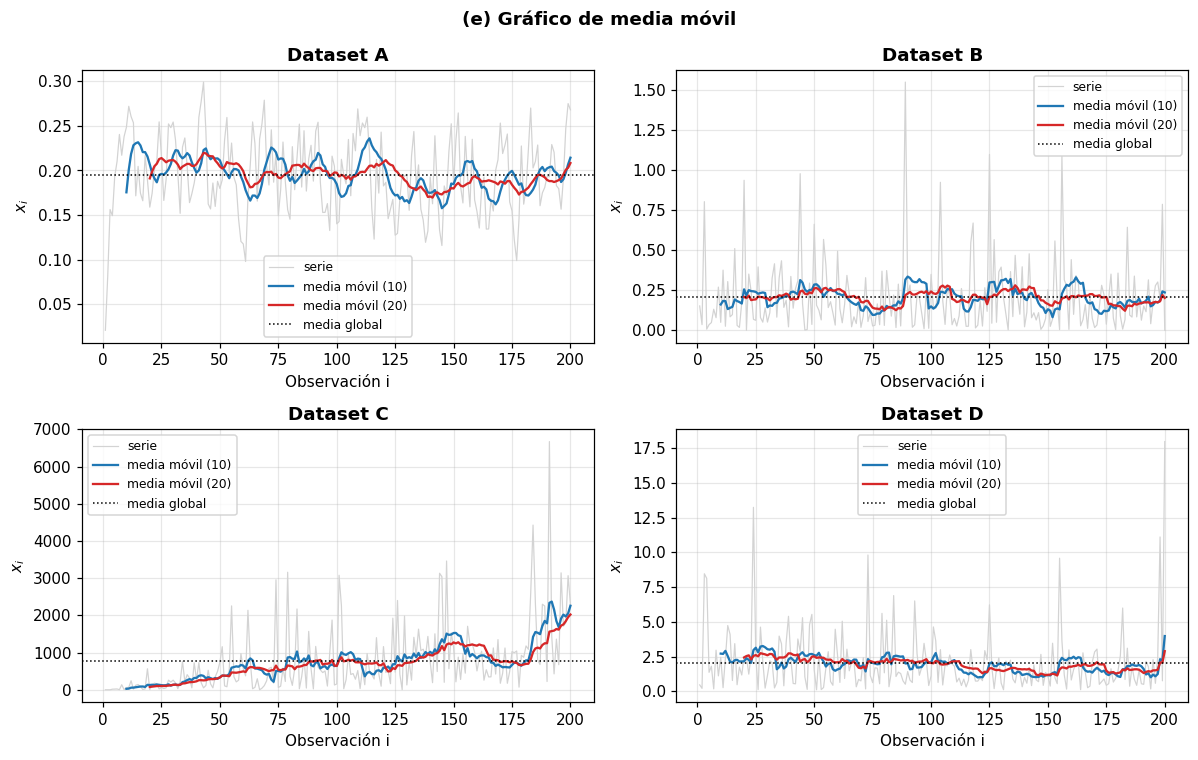

In [11]:
# (e) Media móvil con ventanas de 10 y 20 observaciones
fig, axs = plt.subplots(2, 2, figsize=(11, 7))
for ax, (k, x) in zip(axs.ravel(), datos.items()):
    s = pd.Series(x); idx = np.arange(1, len(x) + 1)
    ax.plot(idx, x, color="lightgray", lw=0.8, label="serie")
    ax.plot(idx, s.rolling(10).mean(), color="#1f77b4", lw=1.5, label="media móvil (10)")
    ax.plot(idx, s.rolling(20).mean(), color="#d62728", lw=1.5, label="media móvil (20)")
    ax.axhline(x.mean(), color="black", ls=":", lw=1, label="media global")
    ax.set_title(f"Dataset {k}"); ax.set_xlabel("Observación i"); ax.set_ylabel("$x_i$"); ax.legend(fontsize=8)
fig.suptitle("(e) Gráfico de media móvil", fontweight="bold")
fig.tight_layout(); fig.savefig("imagenes/moving_average.png", dpi=150, bbox_inches="tight"); plt.show()

In [12]:
# Tabla resumen de los estadísticos de independencia/estacionariedad para el informe
cols = ["rho1", "fuera_banda", "LB_Q", "LB_p", "rachas_Z", "rachas_p", "spearman_rho", "spearman_p",
        "media_1a_mitad", "media_2a_mitad"]
lineas = []
for k, r in tabla_indep.iterrows():
    vals = [f"{r.rho1:.3f}", f"{int(r.fuera_banda)}/{MAX_LAG}", f"{r.LB_Q:.1f}", f"{r.LB_p:.3g}",
            f"{r.rachas_Z:.2f}", f"{r.rachas_p:.3g}", f"{r.spearman_rho:.3f}", f"{r.spearman_p:.3g}",
            f"{r.media_1a_mitad:.4g}", f"{r.media_2a_mitad:.4g}"]
    lineas.append(f"Dataset {k} & " + " & ".join(vals) + r" \\")
with open("tablas/tabla_indep.tex", "w") as f:
    f.write("\n".join(lineas))
tabla_indep[cols]

,rho1,fuera_banda,LB_Q,LB_p,rachas_Z,rachas_p,spearman_rho,spearman_p,media_1a_mitad,media_2a_mitad
A,0.4922,5.0000,83.6925,0.0000,-3.2609,0.0011,-0.1048,0.1397,0.1988,0.1913
B,-0.0923,0.0000,6.9414,0.7310,2.1267,0.0334,-0.0035,0.9610,0.2050,0.2058
C,0.2084,10.0000,110.8847,0.0000,-2.4102,0.0159,0.6034,0.0000,417.5578,"1,107.2299"
D,-0.0024,0.0000,2.7106,0.9874,1.2760,0.2020,-0.1171,0.0987,2.2830,1.8380


## 5.3 Ajuste de curvas y bondad de ajuste

Siguiendo el tutorial de Amat (2021), cada distribución se ajusta por **máxima verosimilitud**
con `scipy.stats.<dist>.fit(x)` y se evalúan
tres métricas:

- **SSE** $=\sum_j \big(h_j - f(c_j;\hat\theta)\big)^2$, donde $h_j$ es la densidad del histograma
  de 20 *bins* y $f(c_j)$ la densidad ajustada en el centro del *bin* $j$.
- **AIC** $= 2p - 2\ln \hat L$ y **BIC** $= p\ln n - 2\ln\hat L$, con $p$ el número de parámetros
  estimados y $\hat L$ la verosimilitud en el máximo.

Como los datos son magnitudes no negativas (tiempos entre llegadas), en las distribuciones de soporte
$[loc,\infty)$ se fija $loc=0$ (`floc=0`) y se estiman sólo los parámetros de forma y escala; la normal y
la Gumbel, definidas en toda la recta, se ajustan con `loc` y `scale` libres. Dejar `loc` libre produce
ajustes degenerados (por ejemplo $loc>\min x$, que anula la verosimilitud, o $loc\to-\infty$ con forma
$\to 0$ para imitar una normal), como se observó en una primera corrida.

Se evalúan las cinco distribuciones de la guía (exponencial, lognormal, normal, gamma y beta) y cuatro
adicionales: **Weibull**, **Rayleigh**, **Gumbel** (valor extremo tipo I) y **Gaussiana inversa**
(Wald), que cubren formas con cola derecha pesada, simétricas y acotadas.

In [13]:
DISTRIBUCIONES = {
    "Exponencial":       st.expon,
    "Lognormal":         st.lognorm,
    "Normal":            st.norm,
    "Gamma":             st.gamma,
    "Beta":              st.beta,
    "Weibull":           st.weibull_min,
    "Rayleigh":          st.rayleigh,
    "Gumbel":            st.gumbel_r,
    "Gaussiana inversa": st.invgauss,
}
N_BINS = 20

def nombres_parametros(dist):
    shapes = dist.shapes.split(", ") if dist.shapes else []
    return shapes + ["loc", "scale"]

# Distribuciones con soporte [loc, inf): como los datos son magnitudes no negativas
# (tiempos entre llegadas), se fija loc = 0 y se estiman solo la forma y la escala.
# Si loc se deja libre, scipy produce ajustes degenerados (loc > min(x) -> verosimilitud nula,
# o loc -> -infinito con forma -> 0 para imitar una normal), como se comprobo en una primera corrida.
SOPORTE_POSITIVO = {"Exponencial", "Lognormal", "Gamma", "Beta", "Weibull", "Rayleigh", "Gaussiana inversa"}

def ajustar(x, dist, nombre):
    params = dist.fit(x, floc=0) if nombre in SOPORTE_POSITIVO else dist.fit(x)
    p_libres = len(params) - (1 if nombre in SOPORTE_POSITIVO else 0)
    h, bordes = np.histogram(x, bins=N_BINS, density=True)
    centros = (bordes[:-1] + bordes[1:]) / 2
    pdf = dist.pdf(centros, *params)
    sse = np.sum((h - pdf) ** 2)
    logL = np.sum(dist.logpdf(x, *params))
    p = p_libres; n = len(x)
    aic = 2 * p - 2 * logL
    bic = p * math.log(n) - 2 * logL
    return params, sse, aic, bic, logL

def tabla_ajuste(x):
    filas = []
    for nombre, dist in DISTRIBUCIONES.items():
        params, sse, aic, bic, logL = ajustar(x, dist, nombre)
        txt = ", ".join(f"{nm}={v:.4g}" for nm, v in zip(nombres_parametros(dist), params))
        filas.append({"Distribución": nombre, "Parámetros": txt, "SSE": sse, "AIC": aic, "BIC": bic,
                      "logL": logL, "_params": params})
    df = pd.DataFrame(filas).set_index("Distribución")
    # ranking combinado: suma de los puestos en SSE, AIC y BIC (menor es mejor)
    df["rank_SSE"] = df["SSE"].rank(); df["rank_AIC"] = df["AIC"].rank(); df["rank_BIC"] = df["BIC"].rank()
    df["Puntaje"] = df["rank_SSE"] + df["rank_AIC"] + df["rank_BIC"]
    return df.sort_values(["Puntaje", "AIC"])

ajustes = {k: tabla_ajuste(x) for k, x in datos.items()}

In [14]:
pd.set_option("display.float_format", lambda v: f"{v:.4g}")
pd.set_option("display.max_colwidth", 70)
for k in "ABCD":
    print(f"\n===== Bondad de ajuste — Dataset {k} =====")
    display(ajustes[k][["Parámetros", "SSE", "AIC", "BIC", "Puntaje"]])


===== Bondad de ajuste — Dataset A =====


,Parámetros,SSE,AIC,BIC,Puntaje
Distribución,,,,,
Normal,"loc=0.195, scale=0.0437",29.15,-680.6,-674,5
Beta,"a=14.49, b=76.15, loc=0, scale=1.217",27.11,-651.7,-641.9,7
Weibull,"c=5.071, loc=0, scale=0.212",32.43,-679.4,-672.8,8
Gamma,"a=16.18, loc=0, scale=0.01206",28.24,-647.3,-640.7,10
Gumbel,"loc=0.1728, scale=0.0491",42.53,-620.4,-613.8,16
Lognormal,"s=0.275, loc=0, scale=0.189",36.97,-611.1,-604.5,17
Gaussiana inversa,"mu=0.08962, loc=0, scale=2.176",48.06,-583.4,-576.8,21
Rayleigh,"loc=0, scale=0.1413",185.2,-497,-493.7,24
Exponencial,"loc=0, scale=0.195",340.5,-251.8,-248.5,27



===== Bondad de ajuste — Dataset B =====


,Parámetros,SSE,AIC,BIC,Puntaje
Distribución,,,,,
Weibull,"c=0.9095, loc=0, scale=0.1963",0.2762,-232.3,-225.7,4
Gamma,"a=0.8636, loc=0, scale=0.2378",0.3158,-232.1,-225.5,7
Exponencial,"loc=0, scale=0.2054",0.4358,-231.1,-227.8,8
Beta,"a=0.8636, b=1.352e+12, loc=0, scale=3.215e+11",0.3158,-230.1,-220.2,11
Lognormal,"s=1.437, loc=0, scale=0.104",2.326,-188.7,-182.1,15
Gumbel,"loc=0.1171, scale=0.132",5.729,-138.4,-131.9,18
Normal,"loc=0.2054, scale=0.2285",11.57,-18.89,-12.29,22
Rayleigh,"loc=0, scale=0.2173",18.12,85.99,89.29,25
Gaussiana inversa,"mu=22.4, loc=0, scale=0.009169",6.528,152,158.6,25



===== Bondad de ajuste — Dataset C =====


,Parámetros,SSE,AIC,BIC,Puntaje
Distribución,,,,,
Gamma,"a=0.7062, loc=0, scale=1080",4.493e-08,3040,3047,5
Weibull,"c=0.8007, loc=0, scale=676",2.524e-08,3041,3047,5
Beta,"a=0.712, b=6.036e+05, loc=0, scale=6.462e+08",4.442e-08,3042,3052,8
Exponencial,"loc=0, scale=762.4",5.978e-08,3057,3060,12
Lognormal,"s=1.648, loc=0, scale=324.3",6.361e-08,3084,3091,15
Gumbel,"loc=409.7, scale=515.2",4.557e-07,3176,3182,19
Normal,"loc=762.4, scale=920.8",9.265e-07,3302,3308,22
Gaussiana inversa,"mu=19.81, loc=0, scale=38.49",3.224e-07,3311,3317,22
Rayleigh,"loc=0, scale=845.3",1.434e-06,3481,3484,27



===== Bondad de ajuste — Dataset D =====


,Parámetros,SSE,AIC,BIC,Puntaje
Distribución,,,,,
Lognormal,"s=1.019, loc=0, scale=1.273",0.006913,675.9,682.5,3
Exponencial,"loc=0, scale=2.06",0.009898,691.2,694.5,9
Gaussiana inversa,"mu=1.763, loc=0, scale=1.169",0.02549,685.4,692,10
Gamma,"a=1.178, loc=0, scale=1.749",0.01048,690,696.6,11
Beta,"a=1.165, b=2.071e+06, loc=0, scale=3.663e+06",0.01036,692,701.9,14
Weibull,"c=1.042, loc=0, scale=2.099",0.01066,692.5,699.1,16
Gumbel,"loc=1.228, scale=1.216",0.0487,756.1,762.7,21
Normal,"loc=2.06, scale=2.321",0.1175,908.3,914.9,24
Rayleigh,"loc=0, scale=2.194",0.1572,934.1,937.4,27


In [15]:
# Tablas en LaTeX (orden de la guía) y ranking para el informe
orden_guia = list(DISTRIBUCIONES.keys())
def tex_num(v):
    return f"{v:.3f}" if abs(v) >= 1e-2 else f"{v:.3e}"

for k in "ABCD":
    df = ajustes[k]
    top3 = list(df.index[:3])
    lineas = []
    for nombre in orden_guia:
        r = df.loc[nombre]
        marca = r"\textbf{" + nombre + "}" if nombre in top3 else nombre
        par = r"\scriptsize " + r["Parámetros"].replace("scale", "esc").replace("_", r"\_")
        lineas.append(f"{marca} & {par} & {tex_num(r.SSE)} & {r.AIC:.2f} & {r.BIC:.2f} & {int(r.Puntaje)} \\\\")
    with open(f"tablas/ajuste_{k}.tex", "w") as f:
        f.write("\n".join(lineas))
    print(f"Dataset {k}: mejores tres → {top3}")

Dataset A: mejores tres → ['Normal', 'Beta', 'Weibull']
Dataset B: mejores tres → ['Weibull', 'Gamma', 'Exponencial']
Dataset C: mejores tres → ['Gamma', 'Weibull', 'Beta']
Dataset D: mejores tres → ['Lognormal', 'Exponencial', 'Gaussiana inversa']


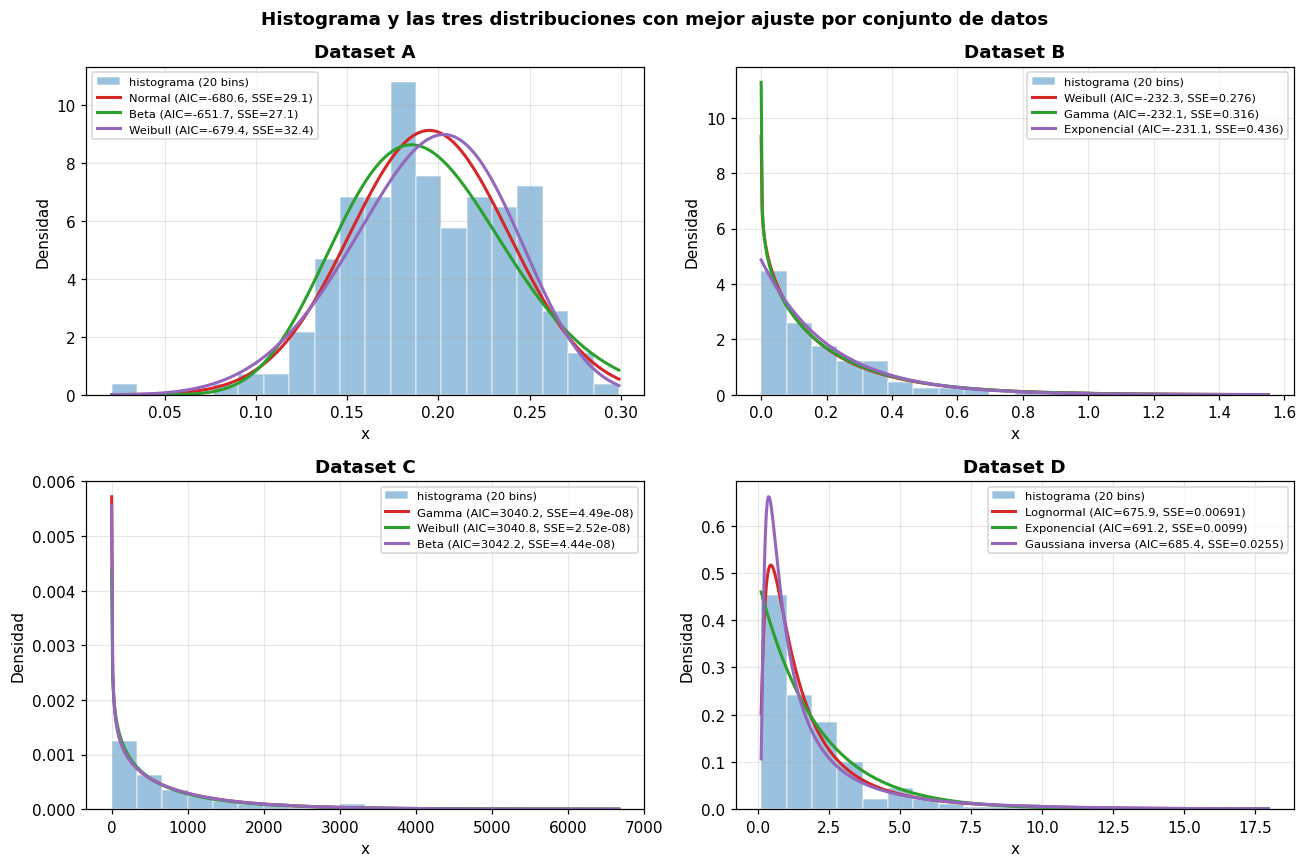

In [16]:
# Figura por conjunto de datos: histograma + las tres distribuciones con mejor ajuste
fig, axs = plt.subplots(2, 2, figsize=(12, 8))
colores = ["#d62728", "#2ca02c", "#9467bd"]
for ax, (k, x) in zip(axs.ravel(), datos.items()):
    df = ajustes[k]
    ax.hist(x, bins=N_BINS, density=True, color="#1f77b4", alpha=0.45, edgecolor="white", label="histograma (20 bins)")
    xs = np.linspace(x.min(), x.max(), 500)
    for (nombre, r), col in zip(df.head(3).iterrows(), colores):
        dist = DISTRIBUCIONES[nombre]
        ax.plot(xs, dist.pdf(xs, *r["_params"]), color=col, lw=2,
                label=f"{nombre} (AIC={r.AIC:.1f}, SSE={r.SSE:.3g})")
    ax.set_title(f"Dataset {k}"); ax.set_xlabel("x"); ax.set_ylabel("Densidad"); ax.legend(fontsize=7.5)
fig.suptitle("Histograma y las tres distribuciones con mejor ajuste por conjunto de datos", fontweight="bold")
fig.tight_layout(); fig.savefig("imagenes/mejores_ajustes.png", dpi=150, bbox_inches="tight"); plt.show()

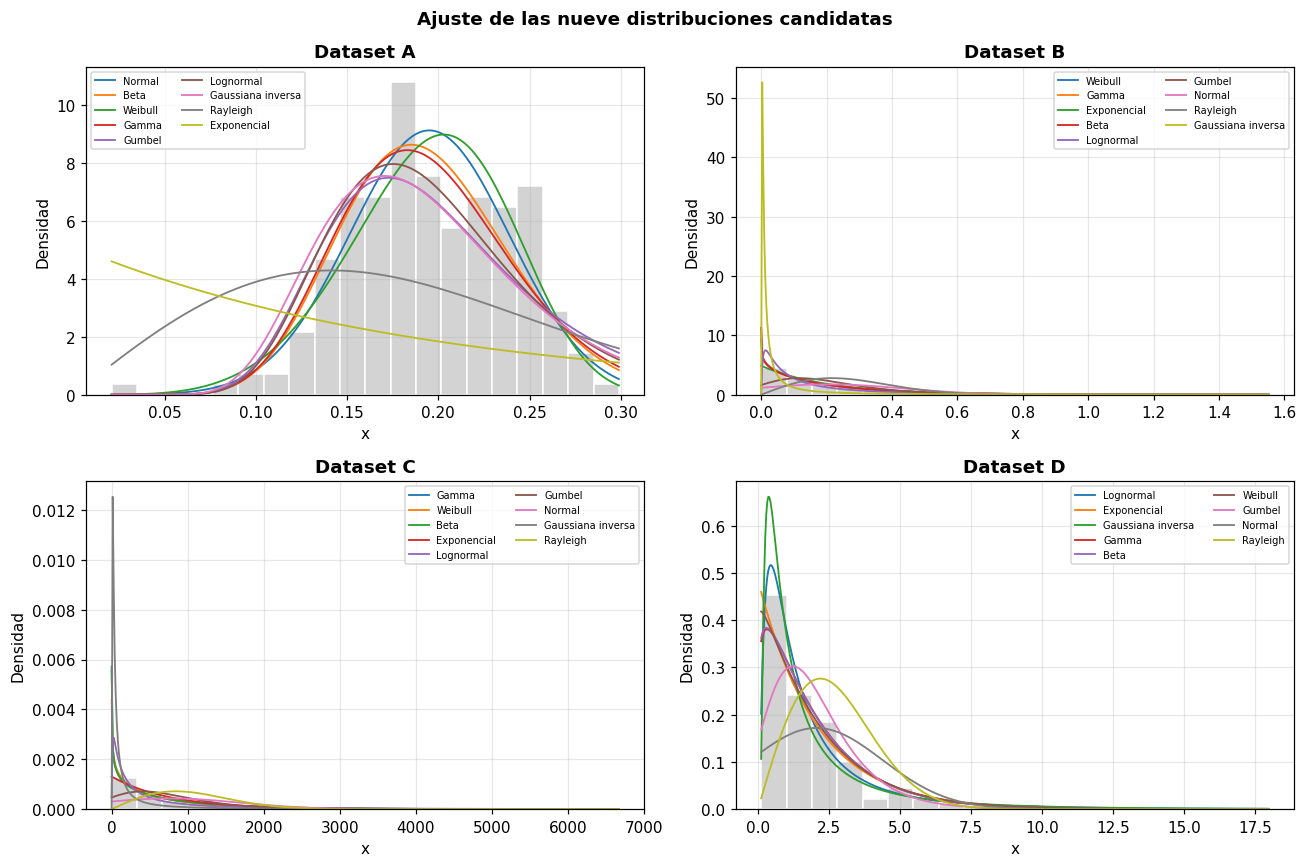

In [17]:
# Figura complementaria: las nueve distribuciones sobre cada histograma
fig, axs = plt.subplots(2, 2, figsize=(12, 8))
for ax, (k, x) in zip(axs.ravel(), datos.items()):
    df = ajustes[k]
    ax.hist(x, bins=N_BINS, density=True, color="lightgray", edgecolor="white")
    xs = np.linspace(x.min(), x.max(), 500)
    for nombre, r in df.iterrows():
        ax.plot(xs, DISTRIBUCIONES[nombre].pdf(xs, *r["_params"]), lw=1.2, label=nombre)
    ax.set_title(f"Dataset {k}"); ax.set_xlabel("x"); ax.set_ylabel("Densidad"); ax.legend(fontsize=6.5, ncol=2)
fig.suptitle("Ajuste de las nueve distribuciones candidatas", fontweight="bold")
fig.tight_layout(); fig.savefig("imagenes/todos_los_ajustes.png", dpi=150, bbox_inches="tight"); plt.show()

In [18]:
# Verificación adicional de la distribución seleccionada: prueba de Kolmogorov–Smirnov
ks = {}
for k, x in datos.items():
    df = ajustes[k]
    filas = {}
    for nombre, r in df.head(3).iterrows():
        D, p = st.kstest(x, DISTRIBUCIONES[nombre].cdf, args=tuple(r["_params"]))
        filas[nombre] = {"KS D": D, "KS p": p}
    ks[k] = pd.DataFrame(filas).T
    print(f"\nDataset {k}"); display(ks[k])


Dataset A


,KS D,KS p
Normal,0.05226,0.6262
Beta,0.05113,0.6534
Weibull,0.06845,0.2924



Dataset B


,KS D,KS p
Weibull,0.03495,0.9604
Gamma,0.03608,0.9486
Exponencial,0.06585,0.3363



Dataset C


,KS D,KS p
Gamma,0.03877,0.913
Weibull,0.03675,0.9407
Beta,0.03976,0.8974



Dataset D


,KS D,KS p
Lognormal,0.05374,0.5913
Exponencial,0.06392,0.3716
Gaussiana inversa,0.09233,0.06196
